# SmartMoney – Fase 3: clasificador de movimientos (Idea 1)

**Objetivo:** dada la descripción que escribe el usuario ("pasaje metrolínea", "nequi a mamá"), predecir uno de los 13 grupos de gasto.

**Diseño experimental**
- **Entrenamiento:** `dataset_entrenamiento.csv`, que tiene frases escritas por el equipo y variaciones generadas automáticamente. No contiene frases de la encuesta.
- **Selección de hiperparámetros:** validación cruzada **solo sobre el entrenamiento**.
- **Prueba:** `encuesta_frases_etiquetadas.csv`, con las frases reales de 72 personas. Se usa **una sola vez**, al final.
- **Modelos comparados:**
  1. Diccionario de palabras clave (línea base sin aprendizaje).
  2. Naive Bayes multinomial (línea base de aprendizaje automático).
  3. **Regresión logística sobre TF-IDF de n-gramas de caracteres** (modelo propuesto).
- **Escenarios de prueba:**
  - *Realista:* todas las frases, excepto las mal etiquetadas.
  - *Exigente:* lo mismo, pero sin las frases genéricas ("mercado", "ropa"…).
  - *Frases nuevas:* frases exigentes que no aparecen literalmente en el entrenamiento.
- **Métricas:** accuracy, F1 macro (métrica principal), F1 por clase, matriz de confusión e intervalo de confianza al 95 % por bootstrap.

## 1. Archivos
Sube `dataset_entrenamiento.csv` y `encuesta_frases_etiquetadas.csv` cuando lo pida la celda (o ponlos en la misma carpeta si corres local).

In [1]:
import os
ARCHIVOS = ["dataset_entrenamiento.csv", "encuesta_frases_etiquetadas.csv"]
faltan = [a for a in ARCHIVOS if not os.path.exists(a)]
if faltan:
    try:
        from google.colab import files
        print("Sube:", faltan)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Faltan {faltan} en la carpeta actual")
print("Archivos listos:", [a for a in ARCHIVOS if os.path.exists(a)])

Archivos listos: ['dataset_entrenamiento.csv', 'encuesta_frases_etiquetadas.csv']


In [2]:
import re, json, math, unicodedata, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA)

GRUPOS = {1:"Mercado",2:"Licor y cigarrillos",3:"Ropa y calzado",4:"Vivienda y servicios",5:"Hogar",6:"Salud",
          7:"Transporte",8:"Celular, internet y suscripciones",9:"Entretenimiento",10:"Educación",
          11:"Comidas fuera y domicilios",12:"Otros gastos personales",13:"Obligaciones y transferencias"}
CORTO = {1:"Mercado",2:"Licor",3:"Ropa",4:"Vivienda",5:"Hogar",6:"Salud",7:"Transp.",8:"Celular",
         9:"Entret.",10:"Educ.",11:"Comidas",12:"Otros",13:"Oblig."}
ETIQ = list(GRUPOS)

def normalizar(s):
    """Minúsculas, sin tildes, solo letras y números. La Edge Function debe hacer EXACTAMENTE lo mismo."""
    s = unicodedata.normalize("NFD", str(s).lower())
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return s.strip()

ent = pd.read_csv("dataset_entrenamiento.csv")
enc = pd.read_csv("encuesta_frases_etiquetadas.csv")
ent["t"] = ent.texto.map(normalizar); enc["t"] = enc.texto.map(normalizar)
print("Entrenamiento:", len(ent), "frases |", ent.grupo_id.value_counts().min(), "a", ent.grupo_id.value_counts().max(), "por grupo")
print("Encuesta:", len(enc), "frases de", enc.respondente.nunique(), "personas")

Entrenamiento: 3380 frases | 260 a 260 por grupo
Encuesta: 720 frases de 72 personas


## 2. Escenarios de prueba (encuesta)

In [3]:
vistos = set(ent.t)
realista  = enc[enc.usar_en_prueba]
exigente  = realista[~realista.generica]
nuevas    = exigente[~exigente.t.isin(vistos)]
ESCENARIOS = {"Realista": realista, "Exigente": exigente, "Frases nuevas": nuevas}
for k, v in ESCENARIOS.items(): print(f"{k:14s} {len(v):4d} frases")
print(f"\nFrases exigentes que también están en el entrenamiento (texto idéntico): {len(exigente)-len(nuevas)} "
      f"({(len(exigente)-len(nuevas))/len(exigente):.0%}). Son palabras comunes como 'arriendo' o 'netflix'.")

Realista        688 frases
Exigente        548 frases
Frases nuevas   352 frases

Frases exigentes que también están en el entrenamiento (texto idéntico): 196 (36%). Son palabras comunes como 'arriendo' o 'netflix'.


## 3. Línea base 1: diccionario de palabras clave
Es lo que haría una app sin IA. Busca palabras clave dentro de la descripción y gana el grupo con más coincidencias. Si no encuentra ninguna, asigna "Otros gastos personales". Las palabras salen de la definición de cada grupo en el formulario, más las más obvias.

In [4]:
DICCIONARIO = {
 1: ["mercado","d1","ara","exito","olimpica","jumbo","carulla","fruta","verdura","leche","huevo","arroz","pan","carne","pollo","granos","tienda","supermercado","viveres"],
 2: ["cerveza","pola","aguardiente","guaro","ron","licor","trago","cigarr","tabaco","vape","vino","whisky"],
 3: ["ropa","camisa","camiseta","pantalon","jean","zapato","tenis","calzado","chaqueta","vestido","medias","sudadera"],
 4: ["arriendo","luz","agua","gas","energia","acueducto","servicios","administracion","recibo","epm","essa","vanti"],
 5: ["aseo","detergente","jabon","ollas","mueble","escoba","trapero","limpido","cloro","papel higienico","hogar","colchon"],
 6: ["drogueria","medicamento","medicina","pastilla","cita","medico","examen","salud","eps","odontolog","dentista","farmacia","laboratorio"],
 7: ["transporte","pasaje","bus","uber","didi","taxi","gasolina","parqueadero","metrolinea","transmilenio","moto","peaje","soat"],
 8: ["recarga","plan","celular","internet","wifi","netflix","spotify","claro","tigo","movistar","disney","suscripcion","datos"],
 9: ["cine","salida","rumba","fiesta","concierto","juego","mascota","perro","gato","entretenimiento","paseo","viaje","gimnasio"],
 10: ["matricula","curso","fotocopia","copias","libro","universidad","colegio","semestre","educacion","cuaderno","impresion","utiles"],
 11: ["almuerzo","rappi","domicilio","cafe","onces","restaurante","desayuno","comida","pizza","hamburguesa","empanada","tinto","cena"],
 12: ["peluqueria","barberia","corte","unas","cuidado personal","regalo","perfume","maquillaje","crema","shampoo","desodorante"],
 13: ["icetex","tarjeta","prestamo","credito","deuda","pila","impuesto","dian","nequi","daviplata","transferencia","envio","giro","cuota"],
}

def tokens_dicc(t):
    return " " + t + " "

def predecir_diccionario(textos):
    pred = []
    for t in textos:
        tt = tokens_dicc(t)
        # palabras cortas (≤ 4 letras) deben coincidir completas; las largas, por prefijo ("cigarr" → "cigarrillos")
        votos = {g: sum(1 for k in kws if ((" " + k + " ") if len(k) <= 4 else (" " + k)) in tt) for g, kws in DICCIONARIO.items()}
        mejor = max(votos, key=lambda g: (votos[g], -g))
        pred.append(mejor if votos[mejor] > 0 else 12)
    return np.array(pred)

print("Ejemplos:", list(zip(["pasaje metrolinea","nequi a mama","corrientazo","polas"],
                            predecir_diccionario(["pasaje metrolinea","nequi a mama","corrientazo","polas"]))))

Ejemplos: [('pasaje metrolinea', np.int64(7)), ('nequi a mama', np.int64(13)), ('corrientazo', np.int64(12)), ('polas', np.int64(12))]


## 4. Modelos con aprendizaje: selección de hiperparámetros
Se usa validación cruzada de 5 particiones **solo con el entrenamiento**. La encuesta no se toca aquí.

- **TF-IDF de n-gramas de caracteres (`char_wb`):** parte cada palabra en pedacitos de 2 a 5 letras, de modo que "rappi", "rapi" y "rapy" comparten pedacitos. Así el modelo tolera errores de ortografía.
- **Regresión logística:** aprende un peso por pedacito y por grupo. `C` controla qué tanto se ajusta a los datos.

In [5]:
def vectorizador(**kw):
    return TfidfVectorizer(preprocessor=normalizar, analyzer="char_wb", sublinear_tf=True, min_df=2, **kw)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
X, y = ent.texto.values, ent.grupo_id.values

busqueda_lr = GridSearchCV(
    Pipeline([("tfidf", vectorizador()), ("clf", LogisticRegression(max_iter=3000))]),
    {"tfidf__ngram_range": [(2,4), (2,5), (3,5)], "clf__C": [1, 5, 10, 30]},
    scoring="f1_macro", cv=cv, n_jobs=-1).fit(X, y)

busqueda_nb = GridSearchCV(
    Pipeline([("tfidf", vectorizador()), ("clf", MultinomialNB())]),
    {"tfidf__ngram_range": [(2,4), (2,5), (3,5)], "clf__alpha": [0.01, 0.05, 0.1, 0.5]},
    scoring="f1_macro", cv=cv, n_jobs=-1).fit(X, y)

print("Regresión logística:", busqueda_lr.best_params_, f"F1 macro en validación = {busqueda_lr.best_score_:.3f}")
print("Naive Bayes:        ", busqueda_nb.best_params_, f"F1 macro en validación = {busqueda_nb.best_score_:.3f}")
print("\nOjo: la validación es con datos del mismo estilo que el entrenamiento, así que sale alta. El resultado que vale es el de la encuesta.")
modelo_lr = busqueda_lr.best_estimator_   # GridSearchCV ya lo reentrenó con todo el entrenamiento
modelo_nb = busqueda_nb.best_estimator_

Regresión logística: {'clf__C': 30, 'tfidf__ngram_range': (2, 5)} F1 macro en validación = 0.948
Naive Bayes:         {'clf__alpha': 0.01, 'tfidf__ngram_range': (3, 5)} F1 macro en validación = 0.930

Ojo: la validación es con datos del mismo estilo que el entrenamiento, así que sale alta. El resultado que vale es el de la encuesta.


## 5. Evaluación con la encuesta (una sola vez)

In [6]:
def bootstrap_f1(y, p, n=2000, semilla=SEMILLA):
    r = np.random.default_rng(semilla); y, p = np.asarray(y), np.asarray(p); v = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        v.append(f1_score(y[i], p[i], average="macro", labels=ETIQ, zero_division=0))
    return np.percentile(v, [2.5, 97.5])

MODELOS = {"Diccionario": lambda d: predecir_diccionario(d.t),
           "Naive Bayes": lambda d: modelo_nb.predict(d.texto),
           "Regresión logística": lambda d: modelo_lr.predict(d.texto)}
filas, PRED = [], {}
for esc, d in ESCENARIOS.items():
    for nom, f in MODELOS.items():
        p = f(d); PRED[(esc, nom)] = p
        lo, hi = bootstrap_f1(d.grupo_id, p)
        filas.append({"Escenario": esc, "Modelo": nom, "n": len(d),
                      "Accuracy": accuracy_score(d.grupo_id, p),
                      "F1 macro": f1_score(d.grupo_id, p, average="macro", labels=ETIQ, zero_division=0),
                      "IC 95 %": f"[{lo:.3f}, {hi:.3f}]"})
resultados = pd.DataFrame(filas)
resultados.style.format({"Accuracy": "{:.3f}", "F1 macro": "{:.3f}"}).hide(axis="index")

Escenario,Modelo,n,Accuracy,F1 macro,IC 95 %
Realista,Diccionario,688,0.730,0.772,"[0.737, 0.800]"
Realista,Naive Bayes,688,0.808,0.798,"[0.763, 0.826]"
Realista,Regresión logística,688,0.810,0.806,"[0.774, 0.835]"
Exigente,Diccionario,548,0.666,0.717,"[0.675, 0.751]"
Exigente,Naive Bayes,548,0.792,0.785,"[0.746, 0.818]"
Exigente,Regresión logística,548,0.797,0.789,"[0.750, 0.823]"
Frases nuevas,Diccionario,352,0.591,0.650,"[0.589, 0.694]"
Frases nuevas,Naive Bayes,352,0.707,0.705,"[0.650, 0.749]"
Frases nuevas,Regresión logística,352,0.713,0.710,"[0.651, 0.754]"


In [7]:
# ¿La regresión logística le gana al diccionario? Bootstrap pareado de la diferencia de F1 macro
def bootstrap_diferencia(y, a, b, n=2000, semilla=SEMILLA):
    r = np.random.default_rng(semilla); y, a, b = map(np.asarray, (y, a, b)); v = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        v.append(f1_score(y[i], a[i], average="macro", labels=ETIQ, zero_division=0)
                 - f1_score(y[i], b[i], average="macro", labels=ETIQ, zero_division=0))
    v = np.array(v); return v.mean(), np.percentile(v, [2.5, 97.5]), (v <= 0).mean()

for esc, d in ESCENARIOS.items():
    for base in ["Diccionario", "Naive Bayes"]:
        m, (lo, hi), p = bootstrap_diferencia(d.grupo_id, PRED[(esc, "Regresión logística")], PRED[(esc, base)])
        print(f"{esc:14s} RL − {base:12s}: {m:+.3f}  IC95 [{lo:+.3f}, {hi:+.3f}]  "
              f"{'✔ diferencia significativa' if lo > 0 else '✘ no concluyente'}")

Realista       RL − Diccionario : +0.034  IC95 [+0.006, +0.064]  ✔ diferencia significativa


Realista       RL − Naive Bayes : +0.008  IC95 [-0.014, +0.029]  ✘ no concluyente


Exigente       RL − Diccionario : +0.074  IC95 [+0.039, +0.108]  ✔ diferencia significativa


Exigente       RL − Naive Bayes : +0.004  IC95 [-0.019, +0.026]  ✘ no concluyente


Frases nuevas  RL − Diccionario : +0.061  IC95 [+0.011, +0.111]  ✔ diferencia significativa


Frases nuevas  RL − Naive Bayes : +0.005  IC95 [-0.029, +0.036]  ✘ no concluyente


## 6. F1 por grupo (escenario exigente)

In [8]:
d = ESCENARIOS["Exigente"]
tabla = pd.DataFrame({"Grupo": [GRUPOS[g] for g in ETIQ],
                      "n": [int((d.grupo_id == g).sum()) for g in ETIQ]})
for nom in MODELOS:
    tabla[nom] = f1_score(d.grupo_id, PRED[("Exigente", nom)], average=None, labels=ETIQ, zero_division=0)
tabla["Nota"] = np.where(tabla.n < 30, "indicativo (n < 30)", "")
tabla.style.format({k: "{:.2f}" for k in MODELOS}).hide(axis="index")

Grupo,n,Diccionario,Naive Bayes,Regresión logística,Nota
Mercado,26,0.77,0.71,0.70,indicativo (n < 30)
Licor y cigarrillos,21,0.73,0.70,0.72,indicativo (n < 30)
Ropa y calzado,27,0.73,0.75,0.75,indicativo (n < 30)
Vivienda y servicios,43,0.83,0.87,0.89,
Hogar,29,0.68,0.79,0.79,indicativo (n < 30)
Salud,31,0.72,0.85,0.83,
Transporte,53,0.86,0.89,0.89,
"Celular, internet y suscripciones",54,0.78,0.90,0.89,
Entretenimiento,62,0.64,0.70,0.71,
Educación,35,0.68,0.76,0.74,


## 7. Matriz de confusión (regresión logística, escenario exigente)

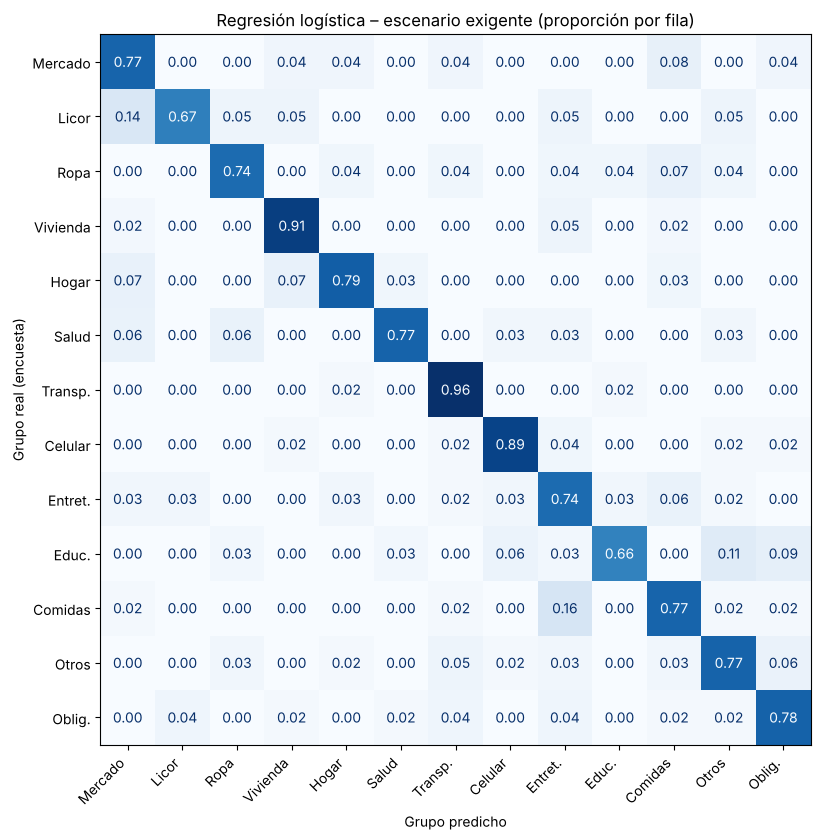

In [9]:
cm = confusion_matrix(d.grupo_id, PRED[("Exigente", "Regresión logística")], labels=ETIQ, normalize="true")
fig, ax = plt.subplots(figsize=(10, 8.5))
ConfusionMatrixDisplay(cm, display_labels=[CORTO[g] for g in ETIQ]).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set_xlabel("Grupo predicho"); ax.set_ylabel("Grupo real (encuesta)")
ax.set_title("Regresión logística – escenario exigente (proporción por fila)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("matriz_confusion_exigente.png", dpi=200); plt.show()

## 8. Análisis de errores
Estos son los errores más frecuentes. Sirven para la discusión de la tesis y para saber qué agregar al entrenamiento.

In [10]:
err = d.assign(pred=PRED[("Exigente", "Regresión logística")])
err = err[err.pred != err.grupo_id]
err["par"] = err.grupo_id.map(CORTO) + " → " + err.pred.map(CORTO)
print("Confusiones más comunes:")
print(err.par.value_counts().head(10).to_string())
print("\nEjemplos:")
print(err[["texto", "grupo_nombre", "pred"]].assign(pred=lambda x: x.pred.map(GRUPOS)).head(25).to_string(index=False))

Confusiones más comunes:
par
Comidas → Entret.    9
Otros → Oblig.       4
Entret. → Comidas    4
Educ. → Otros        4
Educ. → Oblig.       3
Licor → Mercado      3
Otros → Transp.      3
Entret. → Licor      2
Hogar → Mercado      2
Educ. → Celular      2

Ejemplos:
                      texto                  grupo_nombre                              pred
                    Pokemon               Entretenimiento               Licor y cigarrillos
            Pago de nóminas Obligaciones y transferencias                             Salud
                 Quitagrasa                         Hogar                           Mercado
                 Claude pro                     Educación Celular, internet y suscripciones
                       Acai    Comidas fuera y domicilios                        Transporte
            Mercado recibos          Vivienda y servicios                           Mercado
          Pago obligaciones          Vivienda y servicios                   Entretenim

## 9. Confianza del modelo
En la app, el grupo se **sugiere** y el usuario lo confirma o lo corrige. Esta tabla muestra qué tan seguido acierta el modelo según su probabilidad máxima. Sirve para decidir a partir de qué confianza se preselecciona el grupo.

In [11]:
proba = modelo_lr.predict_proba(d.texto); pmax = proba.max(1)
acierto = modelo_lr.classes_[proba.argmax(1)] == d.grupo_id.values
for u in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7]:
    m = pmax >= u
    print(f"confianza ≥ {u:.1f}: cubre {m.mean():5.1%} de las frases, acierta {acierto[m].mean():5.1%}")

confianza ≥ 0.0: cubre 100.0% de las frases, acierta 79.7%
confianza ≥ 0.3: cubre 97.3% de las frases, acierta 81.4%
confianza ≥ 0.4: cubre 92.7% de las frases, acierta 84.1%
confianza ≥ 0.5: cubre 88.1% de las frases, acierta 85.9%
confianza ≥ 0.6: cubre 85.8% de las frases, acierta 86.8%
confianza ≥ 0.7: cubre 80.5% de las frases, acierta 89.6%


## 10. Exportar el modelo a JSON (para la Edge Function)
Se exporta el vocabulario, el IDF, los pesos y los interceptos. Después se comprueba que un predictor escrito **a mano**, sin scikit-learn, da exactamente las mismas probabilidades. Ese predictor es el que se traduce a TypeScript en la Fase 4.

In [12]:
tfidf, clf = modelo_lr.named_steps["tfidf"], modelo_lr.named_steps["clf"]
vocab = tfidf.vocabulary_
orden = sorted(vocab, key=vocab.get)                      # n-gramas en el orden de las columnas
modelo_json = {
    "version": "clasificador-grupos-v1",
    "descripcion": "TF-IDF char_wb + regresión logística multinomial. 13 grupos (12 DANE + obligaciones).",
    "preprocesamiento": "minúsculas → NFD sin marcas diacríticas → [^a-z0-9]+ a espacio → trim",
    "ngram_range": list(tfidf.ngram_range),
    "analizador": "char_wb: por cada palabra w se usa ' '+w+' '; para n de nmin a nmax: si len <= n se agrega la palabra completa una vez y se termina; si no, todos sus n-gramas de tamaño n",
    "sublinear_tf": True, "norma": "l2",
    "clases": [int(c) for c in clf.classes_],
    "nombres": {int(c): GRUPOS[int(c)] for c in clf.classes_},
    "ngramas": orden,
    "idf": [round(float(v), 6) for v in tfidf.idf_],
    "coef": [[round(float(v), 6) for v in fila] for fila in clf.coef_],
    "intercepto": [round(float(v), 6) for v in clf.intercept_],
}

# --- Predictor manual (referencia para TypeScript) ---
def ngramas_char_wb(t, nmin, nmax):
    out = []
    for w in t.split():
        w = " " + w + " "
        for n in range(nmin, nmax + 1):
            if len(w) <= n:          # palabra igual o más corta que n: se cuenta una sola vez y se para
                out.append(w); break
            out.extend(w[i:i+n] for i in range(len(w) - n + 1))
    return out

def predecir_manual(texto, m):
    idx = {g: i for i, g in enumerate(m["ngramas"])}
    cuenta = {}
    for g in ngramas_char_wb(normalizar(texto), *m["ngram_range"]):
        if g in idx: cuenta[idx[g]] = cuenta.get(idx[g], 0) + 1
    x = {i: (1 + math.log(c)) * m["idf"][i] for i, c in cuenta.items()}     # sublinear tf × idf
    nrm = math.sqrt(sum(v * v for v in x.values())) or 1.0
    x = {i: v / nrm for i, v in x.items()}                                   # norma L2
    z = [m["intercepto"][k] + sum(m["coef"][k][i] * v for i, v in x.items()) for k in range(len(m["clases"]))]
    mx = max(z); e = [math.exp(v - mx) for v in z]; s = sum(e)
    return {m["clases"][k]: e[k] / s for k in range(len(e))}                 # softmax

# Verificación contra scikit-learn en toda la encuesta
muestra = enc.texto.tolist()
p_sk = modelo_lr.predict_proba(muestra)
p_man = np.array([[predecir_manual(t, modelo_json)[c] for c in modelo_json["clases"]] for t in muestra])
dif = np.abs(p_sk - p_man).max()
iguales = (p_sk.argmax(1) == p_man.argmax(1)).mean()
print(f"Diferencia máxima de probabilidad: {dif:.2e} | misma predicción en {iguales:.1%} de {len(muestra)} frases")
assert iguales == 1.0 and dif < 1e-3

# Casos de prueba para la Fase 4 (TypeScript debe dar lo mismo)
casos = ["pasaje metrolinea", "Nequi a mamá", "corrientazo", "Recarga Tigo", "pago arriendo", "polas", "rapi", "cuota icetex"]
modelo_json["casos_prueba"] = []
for t in casos:
    pr = predecir_manual(t, modelo_json); g = max(pr, key=pr.get)
    modelo_json["casos_prueba"].append({"texto": t, "normalizado": normalizar(t), "grupo_id": g, "probabilidad": round(pr[g], 4)})
    print(f"{t:20s} → {GRUPOS[g]:35s} {pr[g]:.2f}")

with open("modelo_clasificador.json", "w", encoding="utf-8") as f:
    json.dump(modelo_json, f, ensure_ascii=False, separators=(",", ":"))
print(f"\nmodelo_clasificador.json: {len(orden)} n-gramas × {len(modelo_json['clases'])} clases, "
      f"{os.path.getsize('modelo_clasificador.json')/1024:.0f} KB")

Diferencia máxima de probabilidad: 3.65e-07 | misma predicción en 100.0% de 720 frases
pasaje metrolinea    → Transporte                          1.00
Nequi a mamá         → Obligaciones y transferencias       0.98
corrientazo          → Comidas fuera y domicilios          0.96
Recarga Tigo         → Celular, internet y suscripciones   1.00
pago arriendo        → Vivienda y servicios                1.00
polas                → Licor y cigarrillos                 0.99
rapi                 → Comidas fuera y domicilios          0.89
cuota icetex         → Obligaciones y transferencias       1.00

modelo_clasificador.json: 8631 n-gramas × 13 clases, 1205 KB


## 11. Resumen para la tesis

In [13]:
pivot = resultados.pivot(index="Modelo", columns="Escenario", values="F1 macro")[list(ESCENARIOS)].loc[list(MODELOS)]
print("F1 macro en la encuesta (n = frases reales):")
print(pivot.round(3).to_string())
resultados.to_csv("resultados_fase3.csv", index=False, encoding="utf-8-sig")
tabla.to_csv("f1_por_grupo_exigente.csv", index=False, encoding="utf-8-sig")
try:
    from google.colab import files
    for a in ["modelo_clasificador.json", "resultados_fase3.csv", "f1_por_grupo_exigente.csv", "matriz_confusion_exigente.png"]:
        files.download(a)
except ImportError:
    pass

F1 macro en la encuesta (n = frases reales):
Escenario            Realista  Exigente  Frases nuevas
Modelo                                                
Diccionario             0.772     0.717          0.650
Naive Bayes             0.798     0.785          0.705
Regresión logística     0.806     0.789          0.710
